# Sanity checks for a transient cube (NIGHT `transient.tmpl` output)

**What is a transient cube?** `transient.tmpl` makes one image per 4 s timestep (about 70 per observation) *after subtracting the static sky model* from the visibilities. Stacked together they form a cube with axes **(time, y, x)**, so every pixel has a ~70-point light curve.

* A healthy cube is **noise**: similar rms at every timestep, mean about zero, no stable bright sources left.
* A **transient** is a localised bump in one pixel's light curve (a few timesteps) with nothing before or after.
* **Artefacts** look similar at first glance: bad timesteps, sources the model subtraction missed, ionospheric shifts near bright sources.

This notebook reads the products `<prefix>-cube.fits`, `<prefix>-stdev.fits` (and optionally `<prefix>.hdf5`), runs the checks, and ends with a toy injection test.

**How to use:** edit the config cell. If the files are not found, the notebook runs on a **synthetic demo cube** with problems deliberately injected (a bad timestep, a NaN patch, a static residual source and a real pulse), so you can see what each check is for before pointing it at real data.

> The thresholds used here (e.g. 1.5x rms) are rules of thumb, not pipeline values.

## 0. Configuration

In [22]:
import os, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.time import Time
from astropy.wcs import WCS
from scipy.ndimage import gaussian_filter1d
from pathlib import Path

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "figure.figsize": (7, 4)})
WARN = []          # problems found are collected here and listed at the end

In [23]:
PREFIX    = "1476960704_transient"   # <obsid>_transient
test_path = "test4_Dev_Birli/1476960704/"
DATA_DIR = Path("/scratch/pawsey0272/gcchen" + test_path) # folder holding <prefix>-cube.fits etc.
CUTOUT    = None                     # e.g. (700, 1700, 700, 1700) = (y0, y1, x0, x1); None = whole image
BOX       = 1000                     # side (pixels) of the central box used for noise statistics
INTERACTIVE = False                  # True in Jupyter to get sliders for the pixel light-curve cell

In [24]:
def flag(msg):
    WARN.append(msg); print("  !!", msg)

def mad_rms(a):
    """Robust rms: 1.4826 * median absolute deviation (ignores bright sources and NaNs)."""
    a = np.asarray(a, dtype=np.float64); a = a[np.isfinite(a)]
    return 1.4826 * np.median(np.abs(a - np.median(a))) if a.size else np.nan

## 1. Load the cube (or build a demo cube)

In [25]:
def make_demo(nt=70, n=300, seed=1):
    """Synthetic cube: 10 mJy noise + deliberate problems, so each check has something to find."""
    rng = np.random.default_rng(seed)
    cube = rng.normal(0, 0.010, (nt, n, n)).astype("float32")
    cube[17] *= 3.0                                   # a bad timestep (3x noise)
    cube[5, 200:240, 50:90] = np.nan                  # a NaN patch in one timestep
    yy, xx = np.mgrid[:n, :n]
    blob = lambda y, x, fwhm=4.0: np.exp(-0.5 * ((yy - y)**2 + (xx - x)**2) / (fwhm / 2.355)**2)   # beam-sized source
    cube += (0.08 * blob(60, 60))[None]              # a source the model subtraction missed (constant in time)
    tt = np.arange(nt)
    cube += 0.12 * np.exp(-0.5 * ((tt - 35) / 3.0) ** 2)[:, None, None] * blob(220, 210)[None]   # a real pulse, ~28 s FWHM
    obsid = 1476960704
    hdr = fits.Header()
    hdr.update({"CTYPE1": "RA---SIN", "CTYPE2": "DEC--SIN", "CRVAL1": 340.5, "CRVAL2": -38.3,
                "CRPIX1": n / 2, "CRPIX2": n / 2, "CDELT1": -0.0076, "CDELT2": 0.0076,
                "CUNIT1": "deg", "CUNIT2": "deg", "CTYPE3": "TIME", "CRVAL3": obsid, "CDELT3": 4,
                "DATE-OBS": Time(obsid + 10, format="gps").utc.isot})
    return cube, np.nanstd(cube, axis=0), hdr, WCS(hdr).celestial

cube_path = os.path.join(DATA_DIR, f"{PREFIX}-cube.fits")
std_path  = os.path.join(DATA_DIR, f"{PREFIX}-stdev.fits")
h5_path   = os.path.join(DATA_DIR, f"{PREFIX}.hdf5")
DEMO = not (os.path.exists(cube_path) and os.path.exists(std_path))

if DEMO:
    print("DEMO MODE: real files not found, using a synthetic cube with injected problems.")
    cube, std, hdr, wcs = make_demo()
else:
    hdul = fits.open(cube_path, memmap=True)          # memmap: planes are read from disk only when used
    hdr, cube = hdul[0].header, hdul[0].data
    cube = np.squeeze(cube) if cube.ndim > 3 else cube
    std = np.squeeze(fits.getdata(std_path))
    wcs = WCS(hdr).celestial
    if CUTOUT:
        y0, y1, x0, x1 = CUTOUT
        cube, std = cube[:, y0:y1, x0:x1], std[y0:y1, x0:x1]
        wcs = wcs.slice((slice(y0, y1), slice(x0, x1)))

nt, ny, nx = cube.shape
STEP = float(hdr.get("CDELT3", 4))
b = min(BOX, ny, nx); cy0, cx0 = (ny - b) // 2, (nx - b) // 2
BOXSL = (slice(cy0, cy0 + b), slice(cx0, cx0 + b))
print(f"cube shape (time, y, x) = {cube.shape};  time step = {STEP:g} s;  noise box = {b}x{b} px in the centre")

DEMO MODE: real files not found, using a synthetic cube with injected problems.
cube shape (time, y, x) = (70, 300, 300);  time step = 4 s;  noise box = 300x300 px in the centre


cube shape (time, y, x) = (70, 300, 300);  time step = 4 s;  noise box = 300x300 px in the centre


## 2. Time axis

The cube's `CRVAL3` is set from the **file name (the obsid)**, but the first image starts later (the first and last 8 s are skipped). For absolute times, use each image's `DATE-OBS` or the HDF5 `timestamp` dataset, not `CRVAL3`.

In [26]:
crval3 = hdr.get("CRVAL3")
print(f"CTYPE3={hdr.get('CTYPE3')}  CRVAL3={crval3}  CDELT3={hdr.get('CDELT3')} s")
if hdr.get("DATE-OBS"):
    gps_first = Time(hdr["DATE-OBS"], scale="utc").gps
    off = gps_first - crval3
    print(f"first image DATE-OBS = {hdr['DATE-OBS']}  (GPS {gps_first:.1f}), {off:+.1f} s from CRVAL3")
    if abs(off) > 1:
        flag(f"CRVAL3 is {off:+.1f} s off the first image's DATE-OBS: use DATE-OBS / HDF5 timestamps for absolute times")

CTYPE3=TIME  CRVAL3=1476960704  CDELT3=4 s
first image DATE-OBS = 2026-10-25T10:51:36.000  (GPS 1476960714.0), +10.0 s from CRVAL3
  !! CRVAL3 is +10.0 s off the first image's DATE-OBS: use DATE-OBS / HDF5 timestamps for absolute times


## 3. Per-timestep noise

For each 4 s image, measure the robust rms, the median and the NaN fraction in the central box.

**Healthy:** the rms is roughly flat in time, the median is close to 0, there are no NaNs. Compare the median rms with wsclean's *"Estimated standard deviation of background noise"* in the `.o` log.
**Problem:** a spike or step usually means a bad timestep (check `_summary.txt` for heavy flagging at that time).

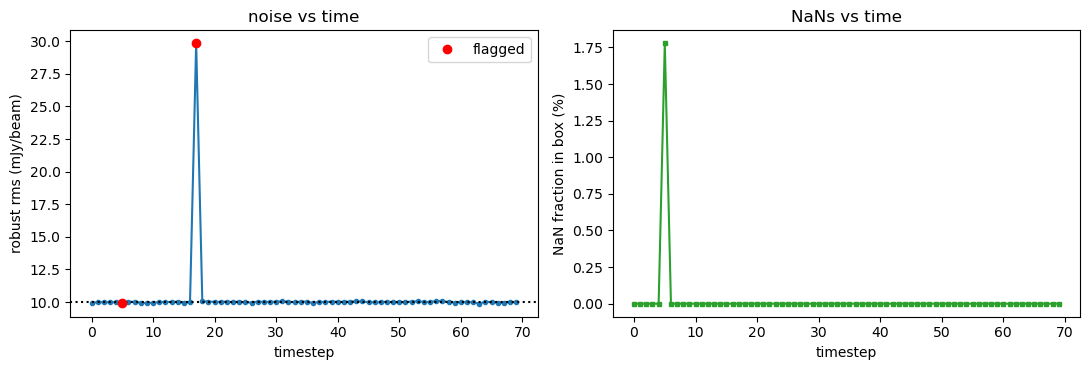

median rms 10.00 mJy/beam  (min 9.87, max 29.84)
  !! 2 odd timestep(s): [5, 17]  (rms off by >50%, >1% NaN, or |median| > 0.5 rms)


In [27]:
rms = np.zeros(nt); med = np.zeros(nt); nanf = np.zeros(nt)
msum = np.zeros((ny, nx)); mcnt = np.zeros((ny, nx))
edges = np.linspace(-8, 8, 81); hist = np.zeros(len(edges) - 1)
for t in range(nt):
    im = np.asarray(cube[t], dtype=np.float64); fin = np.isfinite(im)
    msum += np.where(fin, im, 0.0); mcnt += fin           # running sum for the mean image
    c = im[BOXSL]
    nanf[t] = 1 - np.isfinite(c).mean(); rms[t] = mad_rms(c); med[t] = np.nanmedian(c)
    hist += np.histogram(((c - med[t]) / rms[t])[np.isfinite(c)], bins=edges)[0]
rms_med = np.nanmedian(rms)
bad = np.where((rms > 1.5*rms_med) | (rms < 0.5*rms_med) | (nanf > 0.01) | (np.abs(med) > 0.5*rms))[0]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(rms*1e3, "o-", ms=3); ax[0].axhline(rms_med*1e3, color="k", ls=":")
ax[0].plot(bad, rms[bad]*1e3, "ro", label="flagged"); ax[0].legend()
ax[0].set(xlabel="timestep", ylabel="robust rms (mJy/beam)", title="noise vs time")
ax[1].plot(nanf*100, "s-", ms=3, color="C2"); ax[1].set(xlabel="timestep", ylabel="NaN fraction in box (%)", title="NaNs vs time")
plt.tight_layout(); plt.show()
print(f"median rms {rms_med*1e3:.2f} mJy/beam  (min {np.nanmin(rms)*1e3:.2f}, max {np.nanmax(rms)*1e3:.2f})")
if len(bad):
    flag(f"{len(bad)} odd timestep(s): {bad.tolist()}  (rms off by >50%, >1% NaN, or |median| > 0.5 rms)")
else:
    print("OK: all timesteps similar, no NaNs")

## 4. Mean image, stdev image, pixel histogram

* **Mean image over time**: static sky has been subtracted, so this should look like noise with rms about *rms/sqrt(N)*. A source standing out here was **not removed** by the model subtraction (wrong data column? missing `MODEL_DATA`? phase-centre mismatch?).
* **Stdev image**: the "what varies" map. Its median should be about the per-timestep rms (ratio about 1). A **leftover static source** is high in the mean image but has stdev about equal to the median. A **real transient** is high in the stdev image and only weakly present in the mean (a pulse that is on for only a few of the 70 timesteps adds little to the average). Bright known sources can also show up in the stdev image (calibration or ionospheric wobble).
* **Histogram** of all pixel values over all timesteps: close to a Gaussian, with slightly fat tails being normal.

rms of mean image = 1.26 mJy;  white-noise expectation rms/sqrt(N) = 1.20 mJy;  ratio 1.05
median stdev = 10.31 mJy;  per-timestep rms = 10.00 mJy;  ratio 1.03
  !! mean image has pixels up to 65x rms/sqrt(N): a source was NOT removed by model subtraction


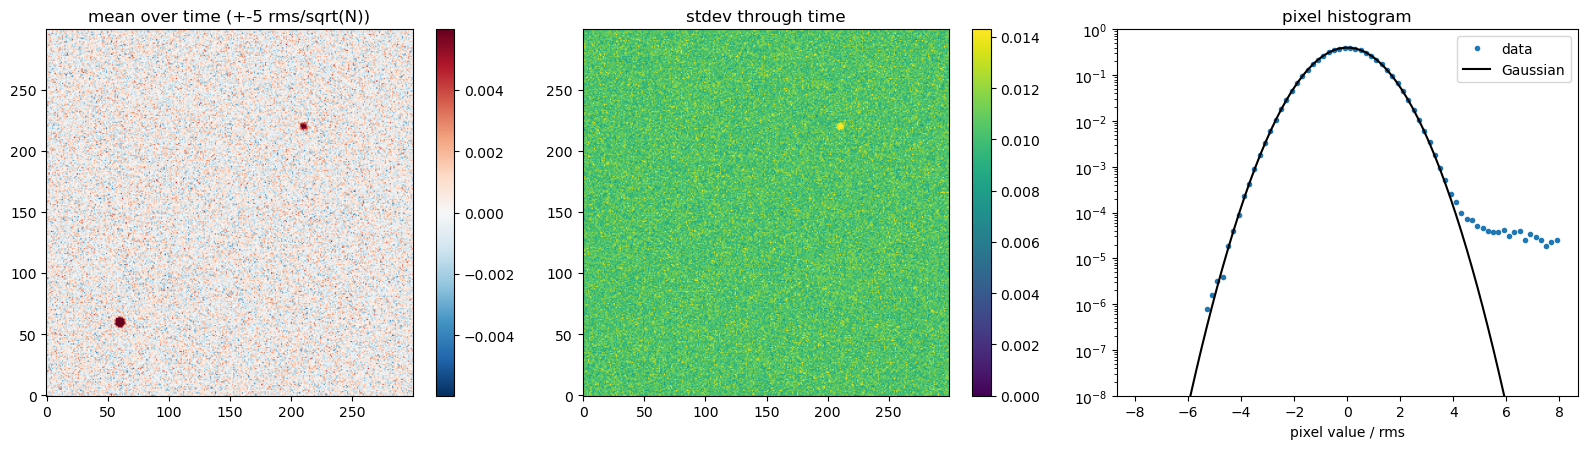

5 highest-stdev peaks:    x     y        RA       Dec   stdev/median   |mean|/(rms/sqrt N)
                         210   220   339.914  -37.759        3.0         11.2
                         220    11   339.802  -39.347        1.8          0.4
                         204   267   339.974  -37.402        1.8          1.7
                          57   197   341.387  -37.932        1.7          0.1
                          50   161   341.458  -38.205        1.7          2.2
(read the last two columns together: high stdev ratio with a modest mean = transient-like or variable; high mean with stdev ratio ~1 = leftover static source)


In [28]:
mean = np.where(mcnt > 0, msum / np.maximum(mcnt, 1), np.nan)
expect = rms_med / np.sqrt(nt)
mean_rms = mad_rms(mean[BOXSL]); smed = np.nanmedian(std[BOXSL])
print(f"rms of mean image = {mean_rms*1e3:.2f} mJy;  white-noise expectation rms/sqrt(N) = {expect*1e3:.2f} mJy;  ratio {mean_rms/expect:.2f}")
print(f"median stdev = {smed*1e3:.2f} mJy;  per-timestep rms = {rms_med*1e3:.2f} mJy;  ratio {smed/rms_med:.2f}")

mabs = np.abs(mean - np.nanmedian(mean[BOXSL])); mabs[~np.isfinite(mabs)] = 0
if mean_rms / expect > 2: flag("mean image much noisier than white noise: static residual structure")
if mabs.max() / expect > 10: flag(f"mean image has pixels up to {mabs.max()/expect:.0f}x rms/sqrt(N): a source was NOT removed by model subtraction")
if not 0.7 < smed / rms_med < 1.3: flag("median stdev differs >30% from per-timestep rms")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
v = 5 * expect
i0 = ax[0].imshow(mean, vmin=-v, vmax=v, cmap="RdBu_r"); ax[0].set_title("mean over time (+-5 rms/sqrt(N))"); plt.colorbar(i0, ax=ax[0])
i1 = ax[1].imshow(std, vmin=0, vmax=np.nanpercentile(std, 99.5)); ax[1].set_title("stdev through time"); plt.colorbar(i1, ax=ax[1])
cen = 0.5 * (edges[1:] + edges[:-1])
ax[2].semilogy(cen, hist/hist.sum()/(cen[1]-cen[0]), "o", ms=3, label="data")
ax[2].semilogy(cen, np.exp(-cen**2/2)/np.sqrt(2*np.pi), "k-", label="Gaussian"); ax[2].set_ylim(1e-8, 1)
ax[2].set(xlabel="pixel value / rms", title="pixel histogram"); ax[2].legend()
plt.tight_layout(); plt.show()

work = np.where(np.isfinite(std), std, 0).copy(); R = 8           # pick 5 distinct peaks (mask 8 px around each)
print("5 highest-stdev peaks:    x     y        RA       Dec   stdev/median   |mean|/(rms/sqrt N)")
for _ in range(5):
    y, x = divmod(int(np.argmax(work)), work.shape[1]); ra, dec = wcs.pixel_to_world_values(x, y)
    print(f"                       {x:5d} {y:5d}  {float(ra):8.3f} {float(dec):8.3f}   {std[y,x]/smed:8.1f}   {mabs[y,x]/expect:10.1f}")
    work[max(0, y-R):y+R+1, max(0, x-R):x+R+1] = 0
print("(read the last two columns together: high stdev ratio with a modest mean = transient-like or variable; high mean with stdev ratio ~1 = leftover static source)")

## 5. Look at a light curve

Numbers only go so far. Plot the strongest-stdev pixel next to a blank control pixel. A pulse shows as a bump over several consecutive timesteps; a bad timestep shows as a single-sample spike; a calibration or ionospheric problem shows as a slow wander.

Set `INTERACTIVE = True` in the config cell (with `ipywidgets` installed) to move the pixel with sliders.

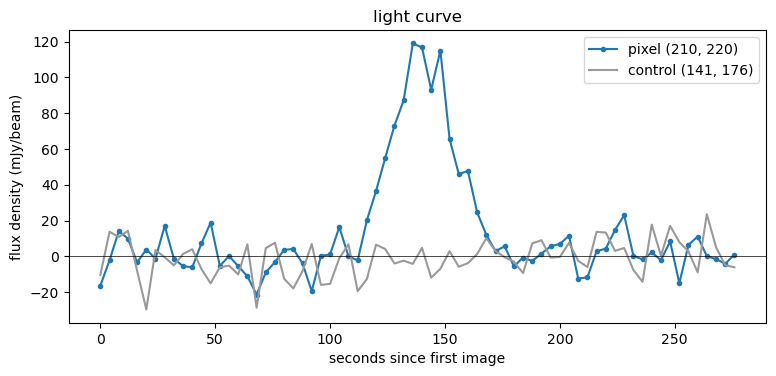

peak deviation = 11.6 x per-timestep rms; stdev/median = 3.0


In [29]:
t_sec = np.arange(nt) * STEP
def plot_pixel(x, y, cx=None, cy=None):
    lc = np.asarray(cube[:, y, x], dtype=np.float64)
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.plot(t_sec, lc*1e3, "o-", ms=3, label=f"pixel ({x}, {y})")
    if cx is not None:
        ax.plot(t_sec, np.asarray(cube[:, cy, cx], dtype=np.float64)*1e3, "-", color="0.6", label=f"control ({cx}, {cy})")
    ax.axhline(0, color="k", lw=0.5); ax.legend()
    ax.set(xlabel="seconds since first image", ylabel="flux density (mJy/beam)", title="light curve")
    plt.show()
    peak = np.nanmax(np.abs(lc - np.nanmedian(lc))) / rms_med
    print(f"peak deviation = {peak:.1f} x per-timestep rms; stdev/median = {std[y, x]/smed:.1f}")

iy, ix = np.unravel_index(np.nanargmax(np.where(np.isfinite(std), std, -1)), std.shape)
cyy, cxx = divmod(int(np.nanargmin(np.abs(np.where(np.isfinite(std), std, np.inf) - smed))), nx)   # a "typical" pixel
plot_pixel(ix, iy, cxx, cyy)

if INTERACTIVE:
    try:
        import ipywidgets as w
        w.interact(lambda x, y: plot_pixel(x, y, cxx, cyy),
                   x=w.IntSlider(min=0, max=nx-1, value=int(ix), continuous_update=False),
                   y=w.IntSlider(min=0, max=ny-1, value=int(iy), continuous_update=False))
    except ImportError:
        print("ipywidgets not installed; call plot_pixel(x, y) by hand instead")

## 6. Toy injection test: would a pulse of this strength be visible?

The best sanity check of a search pipeline is to **inject a fake pulse and see whether it comes out**. Here a Gaussian pulse (FWHM in time and a beam-sized spatial profile) is added to a blank region of the cube, then a simple **matched filter in time** (smoothing each pixel's light curve with a Gaussian of the same width) is applied and the peak signal-to-noise is read off.

This is only an illustration of the idea (similar in spirit to the `tcg` filter in `tfilter.tmpl`). It is **not** the real `DoFilter.py`, whose parameters and noise handling differ. To test the actual pipeline, write the injected cube to an HDF5 and run `obs_tfilter.sh` on it.

Parameters: pulse FWHM = 20 s; spatial FWHM = 4 px (a guess of your beam in pixels: adjust it to match the restored beam in the wsclean log divided by your pixel size).

noise in test region ~ 10.1 mJy/beam per timestep;  pulse FWHM = 20 s = 5.0 timesteps
expected filter gain for this geometry ~ 1.9 x (peak/rms); single pixels scatter by about +-1 around it

peak flux (x rms)   single-timestep S/N   matched-filter S/N: median (min-max) over 25 sites
           2                   2.0              3.8   (2.1-5.9)
           3                   3.0              5.6   (3.9-7.8)
           4                   4.0              7.5   (5.7-9.7)
           6                   6.0             11.2   (9.5-13.4)
          10                  10.0             18.6   (17.1-20.9)

Without injection, pixels above 5 sigma in this 120x120 region: 32  (max 7.2)
After blanking the 2 flagged timestep(s) [5, 17]: pixels above 5 sigma = 0  (max 4.9)
-> a bad timestep makes false 'detections' across the whole image, so flag it before filtering.


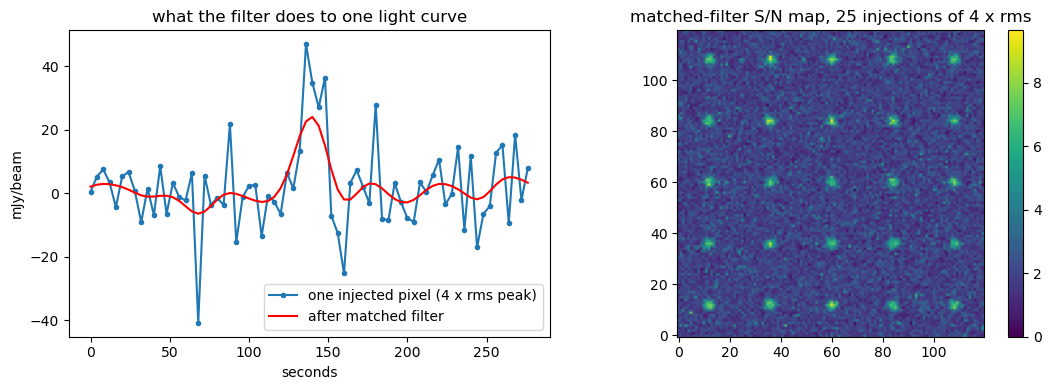

A pulse hard to see in any single 4 s image (~3-4 x rms) can stand out in the filtered map; that is why the pipeline filters in time.


           6                   6.0             11.2   (9.5-13.4)
          10                  10.0             18.6   (17.1-20.9)



Without injection, pixels above 5 sigma in this 120x120 region: 32  (max 7.2)
After blanking the 2 flagged timestep(s) [5, 17]: pixels above 5 sigma = 0  (max 4.9)
-> a bad timestep makes false 'detections' across the whole image, so flag it before filtering.


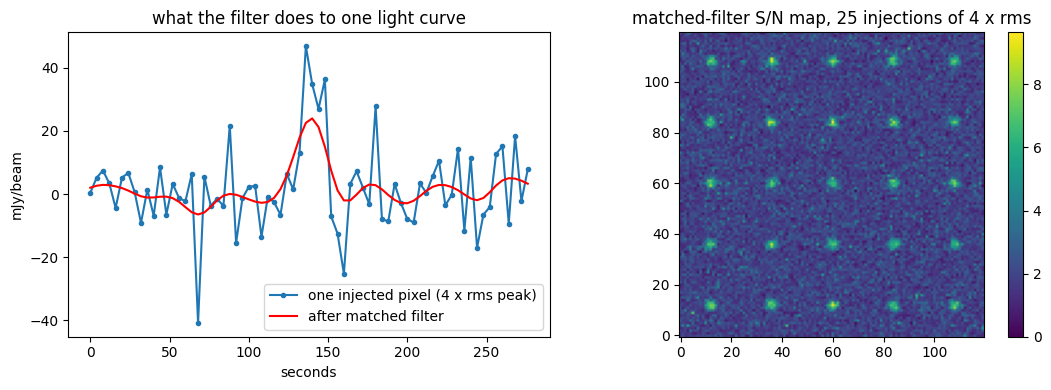

A pulse hard to see in any single 4 s image (~3-4 x rms) can stand out in the filtered map; that is why the pipeline filters in time.


In [30]:
FWHM_T, PIX_FWHM, HALF = 20.0, 4.0, 60                   # pulse width (s), spatial FWHM (px), half-size of test region
cy_c, cx_c = ny // 2, nx // 2                             # test region sits in the middle of the field
y_a, y_b, x_a, x_b = cy_c-HALF, cy_c+HALF, cx_c-HALF, cx_c+HALF
sub0 = np.nan_to_num(np.asarray(cube[:, y_a:y_b, x_a:x_b], dtype=np.float32))
sig_t = FWHM_T / 2.355 / STEP                             # temporal sigma in timesteps
sig_p = PIX_FWHM / 2.355
yy, xx = np.mgrid[:2*HALF, :2*HALF]
# 25 injection sites on a grid (24 px apart, far enough that the pulses do not overlap); results are medians over sites
sites = [(y, x) for y in range(12, 2*HALF-6, 24) for x in range(12, 2*HALF-6, 24)]
spatial = sum(np.exp(-0.5*((yy-y)**2 + (xx-x)**2)/sig_p**2) for y, x in sites)
tprof = np.exp(-0.5*((np.arange(nt) - nt/2)/sig_t)**2)

def matched_filter_snr(sub):
    # mode="constant" (zero padding): "nearest" repeats the edge sample and inflates the noise at the ends of the
    # time series, which creates false detections in the first and last few timesteps
    f = gaussian_filter1d(sub, sigma=sig_t, axis=0, mode="constant")     # matched filter along time
    return f.max(axis=0) / mad_rms(f)                                     # peak over time / noise of the filtered cube

noise_ref = mad_rms(sub0[nt//2])
theory = np.sqrt(0.5) * np.sqrt(2*np.sqrt(np.pi)*sig_t)   # filter gain for a Gaussian pulse and an equal-width kernel
print(f"noise in test region ~ {noise_ref*1e3:.1f} mJy/beam per timestep;  pulse FWHM = {FWHM_T:g} s = {FWHM_T/STEP:.1f} timesteps")
print(f"expected filter gain for this geometry ~ {theory:.1f} x (peak/rms); single pixels scatter by about +-1 around it\n")
print("peak flux (x rms)   single-timestep S/N   matched-filter S/N: median (min-max) over", len(sites), "sites")
results = {}
for amp in (2, 3, 4, 6, 10):
    sub = sub0 + (amp * noise_ref) * tprof[:, None, None] * spatial[None]
    snr = matched_filter_snr(sub); results[amp] = snr
    vals = np.array([snr[y, x] for y, x in sites])
    print(f"{amp:12d}        {amp:14.1f}          {np.median(vals):7.1f}   ({vals.min():.1f}-{vals.max():.1f})")

base = matched_filter_snr(sub0)
print(f"\nWithout injection, pixels above 5 sigma in this {2*HALF}x{2*HALF} region: {(base > 5).sum()}  (max {base.max():.1f})")
sub_clean = sub0.copy(); sub_clean[bad] = 0                              # blank the timesteps flagged in section 3
base2 = matched_filter_snr(sub_clean)
print(f"After blanking the {len(bad)} flagged timestep(s) {bad.tolist()}: pixels above 5 sigma = {(base2 > 5).sum()}  (max {base2.max():.1f})")
print("-> a bad timestep makes false 'detections' across the whole image, so flag it before filtering.")

y1, x1 = sites[len(sites)//2]
lc = (sub0 + (4*noise_ref)*tprof[:, None, None]*spatial[None])[:, y1, x1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t_sec, lc*1e3, "o-", ms=3, label="one injected pixel (4 x rms peak)")
ax[0].plot(t_sec, gaussian_filter1d(lc, sig_t, mode="constant")*1e3, "r-", label="after matched filter")
ax[0].set(xlabel="seconds", ylabel="mJy/beam", title="what the filter does to one light curve"); ax[0].legend()
im = ax[1].imshow(results[4], vmin=0, vmax=max(8, results[4].max())); plt.colorbar(im, ax=ax[1])
ax[1].set_title(f"matched-filter S/N map, {len(sites)} injections of 4 x rms")
plt.tight_layout(); plt.show()
print("A pulse hard to see in any single 4 s image (~3-4 x rms) can stand out in the filtered map; that is why the pipeline filters in time.")

## 7. HDF5 cross-check (optional)

Checks that `make_imstack.py`'s HDF5 agrees with the cube and that its timestamps are 4 s apart.

In [31]:
if os.path.exists(h5_path) and not DEMO:
    import h5py
    with h5py.File(h5_path, "r") as f:
        print("datasets:", {k: f[k].shape for k in f.keys()}, "\nattrs:", dict(f.attrs))
        ts = np.array([Time(s.decode(), scale="utc").gps for s in f["timestamp"][:]]); d = np.diff(ts)
        print(f"timestamps: n={len(ts)}, spacing {d.min():.1f}-{d.max():.1f} s; first = GPS {ts[0]:.1f}")
        if len(ts) != nt: flag(f"HDF5 has {len(ts)} timesteps, cube has {nt}")
        if d.size and np.ptp(d) > 0.5: flag("uneven timestamp spacing in HDF5")
        for t in sorted({0, nt//2, nt-1}):
            hsl = f["image"][0, :, :, 0, t][(slice(CUTOUT[0], CUTOUT[1]), slice(CUTOUT[2], CUTOUT[3]))] if CUTOUT else f["image"][0, :, :, 0, t]
            dd = np.nanmax(np.abs(hsl.astype(np.float64) - np.asarray(cube[t], dtype=np.float64)))
            print(f"  timestep {t}: max |hdf5 - cube| = {dd/rms_med:.4f} x rms (float16 rounding should be tiny)")
            if dd / rms_med > 0.05: flag(f"HDF5 and cube disagree at timestep {t}")
else:
    print("skipped (demo mode or no HDF5 file found)")

skipped (demo mode or no HDF5 file found)


## 8. Summary

In [32]:
print("Things to look at:" if WARN else "No problems flagged by these checks.")
for w_ in WARN: print("  -", w_)
if DEMO:
    print("\n(Demo mode: these are the problems deliberately injected, plus the CRVAL3 offset every real cube has.)")

Things to look at:
  - CRVAL3 is +10.0 s off the first image's DATE-OBS: use DATE-OBS / HDF5 timestamps for absolute times
  - 2 odd timestep(s): [5, 17]  (rms off by >50%, >1% NaN, or |median| > 0.5 rms)
  - mean image has pixels up to 65x rms/sqrt(N): a source was NOT removed by model subtraction

(Demo mode: these are the problems deliberately injected, plus the CRVAL3 offset every real cube has.)


### What the checks do **not** tell you

They show the cube is sane (noise-like, subtraction worked, timesteps good). They do **not** prove that real transients would be found: for that, inject into the actual pipeline (section 6 idea) and compare against known variable sources or pulsars in the field. A source in the stdev image is also not automatically a transient: bright known sources vary because of calibration and the ionosphere.